In [2]:
from pathlib import Path
import sys

if Path('/content').exists():
    ROOT = Path('/content/woodbench')
else:
    ROOT = Path.cwd()

sys.path.insert(0, str(ROOT))

while ROOT != ROOT.parent and not (ROOT / 'docs' / 'references' / 'WoodID_plan.md').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
print(f'[ROOT] {ROOT}')

[ROOT] /home/sakana/Code/ManifoldsTeam/woodbench


# WoodID-S2-2026 — Phase 1 Leakage Origin Investigation

Notebook này kiểm tra nguyên nhân `100% val acc` theo 4 hướng dễ giải thích:

- Origin/specimen leakage: nhiều crop từ cùng mẫu gốc bị rơi vào nhiều split.
- Re-split theo group: đề xuất chia lại sao cho một mẫu gốc chỉ thuộc một split.
- 1-NN retrieval baseline: tìm ảnh train gần nhất với từng ảnh val/test.
- Origin coverage: đo bao nhiêu ảnh val/test có mẫu gốc đã xuất hiện trong train.

Tài liệu đối chiếu: `docs/references/WoodID_plan.md`, `docs/references/WoodID_Assignment_S2.docx`, `docs/references/tree.txt`.

In [2]:
if Path('/content').exists():
    !pip install -q pandas numpy matplotlib seaborn scikit-learn pillow tqdm huggingface_hub

In [3]:
import hashlib
import re
import shutil
from collections import Counter, defaultdict
from dataclasses import dataclass

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

IMG_EXTS = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp', '.webp'}

DATA_ROOT_ORIGINAL = ROOT / 'data' / 'task-B'
DATA_ROOT_CLEAN = ROOT / 'data' / 'task-B-clean'
REPORT_DIR = ROOT / 'docs' / 'reports' / 'phase_1_leakage_origin_investigation'
REPORT_DIR.mkdir(parents=True, exist_ok=True)

for p in [DATA_ROOT_ORIGINAL, DATA_ROOT_CLEAN]:
    print(f'{p}: exists={p.exists()}')
print(f'[report] {REPORT_DIR}')

/home/sakana/Code/ManifoldsTeam/woodbench/data/task-B: exists=True
/home/sakana/Code/ManifoldsTeam/woodbench/data/task-B-clean: exists=False
[report] /home/sakana/Code/ManifoldsTeam/woodbench/docs/reports/phase_1_leakage_origin_investigation


In [4]:
# Optional Colab dataset download. Local runs use existing data/.
if Path('/content').exists() and not DATA_ROOT_ORIGINAL.exists():
    from huggingface_hub import snapshot_download
    snapshot_download(repo_id='ny0g507h3p/wood-task-B', repo_type='dataset', local_dir=str(DATA_ROOT_ORIGINAL))

## 1. Collect Image Manifest

Tạo bảng manifest gồm split, class, path, filename, hash, và origin key. `origin_key` là cách gom các crop cùng mẫu gốc, ví dụ bỏ phần `(12)` trong tên file.

In [5]:
def file_md5(path: Path, chunk_size: int = 1 << 20) -> str:
    h = hashlib.md5()
    with path.open('rb') as f:
        for chunk in iter(lambda: f.read(chunk_size), b''):
            h.update(chunk)
    return h.hexdigest()


def infer_origin_key(path: Path) -> str:
    stem = path.stem
    # Common crop pattern: "species.sample.(crop_id)" -> "species.sample".
    stem = re.sub(r'\s*\(\d+\)$', '', stem)
    # Keep class name in the key to avoid cross-class false positives for numeric filenames.
    return f'{path.parent.name}::{stem}'


def collect_manifest(data_root: Path, compute_hash: bool = True) -> pd.DataFrame:
    rows = []
    for split in ['train', 'val', 'test']:
        split_dir = data_root / split
        if not split_dir.exists():
            continue
        for class_dir in sorted(d for d in split_dir.iterdir() if d.is_dir()):
            for path in sorted(class_dir.iterdir()):
                if not path.is_file() or path.suffix.lower() not in IMG_EXTS:
                    continue
                rows.append({
                    'dataset': data_root.name,
                    'split': split,
                    'class_name': class_dir.name,
                    'filename': path.name,
                    'origin_key': infer_origin_key(path),
                    'md5': file_md5(path) if compute_hash else None,
                    'path': str(path.relative_to(ROOT)),
                })
    return pd.DataFrame(rows)


manifests = []
for data_root in [DATA_ROOT_ORIGINAL, DATA_ROOT_CLEAN]:
    if data_root.exists():
        df = collect_manifest(data_root, compute_hash=True)
        manifests.append(df)
        out_path = REPORT_DIR / f'{data_root.name}_manifest.csv'
        df.to_csv(out_path, index=False)
        print(f'{data_root.name}: {len(df)} images -> {out_path}')

manifest = pd.concat(manifests, ignore_index=True) if manifests else pd.DataFrame()
display(manifest.head())

task-B: 5830 images -> /home/sakana/Code/ManifoldsTeam/woodbench/docs/reports/phase_1_leakage_origin_investigation/task-B_manifest.csv
task-B-clean: 5572 images -> /home/sakana/Code/ManifoldsTeam/woodbench/docs/reports/phase_1_leakage_origin_investigation/task-B-clean_manifest.csv


,dataset,split,class_name,filename,origin_key,md5,path
0,task-B,train,Araucaria araucana,3351. Araucaria araucana.1.(1).png,Araucaria araucana::3351. Araucaria araucana.1.,68cd4a498d259b686e9011413a52aec6,data/task-B/train/Araucaria araucana/3351. Ara...
1,task-B,train,Araucaria araucana,3351. Araucaria araucana.1.(12).png,Araucaria araucana::3351. Araucaria araucana.1.,91e5eaf12f7868ad50e909159b05dc1f,data/task-B/train/Araucaria araucana/3351. Ara...
2,task-B,train,Araucaria araucana,3351. Araucaria araucana.1.(13).png,Araucaria araucana::3351. Araucaria araucana.1.,8266b214b7b772b91c77770d4f1d2d1d,data/task-B/train/Araucaria araucana/3351. Ara...
3,task-B,train,Araucaria araucana,3351. Araucaria araucana.1.(14).png,Araucaria araucana::3351. Araucaria araucana.1.,07cedff4de522ee3eed3a77e8fa3b6af,data/task-B/train/Araucaria araucana/3351. Ara...
4,task-B,train,Araucaria araucana,3351. Araucaria araucana.1.(16).png,Araucaria araucana::3351. Araucaria araucana.1.,636704803afe4a9baa19803f3616d37f,data/task-B/train/Araucaria araucana/3351. Ara...


## 2. Origin/Specimen Leakage

Nếu cùng `origin_key` xuất hiện ở train và val/test, validation không còn là mẫu hoàn toàn mới. Đây là loại leakage tinh vi hơn exact duplicate.

In [6]:
def overlap_summary(df: pd.DataFrame, key_col: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    grouped = (
        df.groupby(['dataset', key_col])
        .agg(
            splits=('split', lambda x: ','.join(sorted(set(x)))),
            n_images=('path', 'count'),
            classes=('class_name', lambda x: ','.join(sorted(set(x)))),
            examples=('path', lambda x: ' | '.join(list(x)[:5])),
        )
        .reset_index()
    )
    grouped['n_splits'] = grouped['splits'].str.count(',') + 1
    overlaps = grouped[grouped['n_splits'] > 1].copy()
    summary = (
        overlaps.groupby('dataset')
        .agg(overlap_groups=(key_col, 'count'), images_in_overlap_groups=('n_images', 'sum'))
        .reset_index()
    )
    totals = df.groupby('dataset').size().rename('total_images').reset_index()
    summary = summary.merge(totals, on='dataset', how='right').fillna(0)
    summary['overlap_image_pct'] = 100 * summary['images_in_overlap_groups'] / summary['total_images']
    return summary, overlaps


hash_summary, hash_overlaps = overlap_summary(manifest, 'md5')
origin_summary, origin_overlaps = overlap_summary(manifest, 'origin_key')

print('Exact duplicate overlap by MD5')
display(hash_summary)
print('Origin/specimen overlap')
display(origin_summary)

hash_overlaps.to_csv(REPORT_DIR / 'md5_overlap_groups.csv', index=False)
origin_overlaps.to_csv(REPORT_DIR / 'origin_overlap_groups.csv', index=False)
display(origin_overlaps.sort_values(['dataset', 'n_images'], ascending=[True, False]).head(20))

Exact duplicate overlap by MD5


,dataset,overlap_groups,images_in_overlap_groups,total_images,overlap_image_pct
0,task-B,120.0,248.0,5830,4.253859
1,task-B-clean,0.0,0.0,5572,0.000000


Origin/specimen overlap


,dataset,overlap_groups,images_in_overlap_groups,total_images,overlap_image_pct
0,task-B,361,5634,5830,96.638079
1,task-B-clean,361,5376,5572,96.482412


,dataset,origin_key,splits,n_images,classes,examples,n_splits
135,task-B,Calocedrus sp::Calocedrus sp._3244.1,"test,train,val",238,Calocedrus sp,data/task-B/train/Calocedrus sp/Calocedrus sp....,3
243,task-B,Cupressus funebris (Cupressus pendula)::Cupres...,"test,train,val",163,Cupressus funebris (Cupressus pendula),data/task-B/train/Cupressus funebris (Cupressu...,3
242,task-B,Cupressus funebris (Cupressus pendula)::Cupres...,"test,train,val",155,Cupressus funebris (Cupressus pendula),data/task-B/train/Cupressus funebris (Cupressu...,3
505,task-B,Pinus sp::Pinus sp._3325.1,"test,train,val",110,Pinus sp,data/task-B/train/Pinus sp/Pinus sp._3325.1 (1...,3
506,task-B,Pinus sp::Pinus sp._3325.2,"test,train,val",106,Pinus sp,data/task-B/train/Pinus sp/Pinus sp._3325.2 (1...,3
479,task-B,Pinus dalatensis::3393. Pinus dalatensis.4,"test,train,val",38,Pinus dalatensis,data/task-B/train/Pinus dalatensis/3393. Pinus...,3
496,task-B,Pinus radiata::3379. Pinus radiata.10,"test,train,val",38,Pinus radiata,data/task-B/train/Pinus radiata/3379. Pinus ra...,3
140,task-B,Chamaecyparis obtusa::3364. Chamaecyparis obtu...,"test,train,val",37,Chamaecyparis obtusa,data/task-B/train/Chamaecyparis obtusa/3364. C...,3
153,task-B,Cryptomeria japonica::3350. Cryptomeria japoni...,"test,train,val",37,Cryptomeria japonica,data/task-B/train/Cryptomeria japonica/3350. C...,3
485,task-B,Pinus krempfii::3384. Pinus krempfii,"test,train,val",37,Pinus krempfii,data/task-B/train/Pinus krempfii/3384. Pinus k...,3


## 3. Origin Coverage

Coverage trả lời câu hỏi: trong val/test có bao nhiêu ảnh có mẫu gốc đã xuất hiện trong train? Coverage càng cao thì val/test càng giống dữ liệu train.

,dataset,split,images,images_with_origin_seen_in_train,coverage_pct,unique_origins,unique_origins_seen_in_train
0,task-B,val,933,912,97.749196,305,284
1,task-B,test,924,902,97.619048,297,275
2,task-B-clean,val,926,905,97.732181,305,284
3,task-B-clean,test,851,829,97.414806,293,271


Saved: /home/sakana/Code/ManifoldsTeam/woodbench/docs/reports/phase_1_leakage_origin_investigation/origin_coverage.png


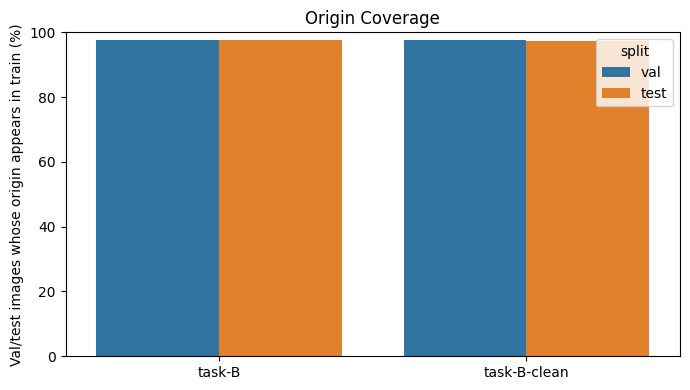

In [7]:
def origin_coverage(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for dataset, g in df.groupby('dataset'):
        train_origins = set(g.loc[g['split'] == 'train', 'origin_key'])
        for split in ['val', 'test']:
            sg = g[g['split'] == split].copy()
            if sg.empty:
                continue
            covered = sg['origin_key'].isin(train_origins)
            rows.append({
                'dataset': dataset,
                'split': split,
                'images': len(sg),
                'images_with_origin_seen_in_train': int(covered.sum()),
                'coverage_pct': 100 * float(covered.mean()),
                'unique_origins': sg['origin_key'].nunique(),
                'unique_origins_seen_in_train': sg.loc[covered, 'origin_key'].nunique(),
            })
    return pd.DataFrame(rows)


coverage = origin_coverage(manifest)
coverage.to_csv(REPORT_DIR / 'origin_coverage.csv', index=False)
display(coverage)

if not coverage.empty:
    plt.figure(figsize=(7, 4))
    sns.barplot(data=coverage, x='dataset', y='coverage_pct', hue='split')
    plt.ylim(0, 100)
    plt.ylabel('Val/test images whose origin appears in train (%)')
    plt.xlabel('')
    plt.title('Origin Coverage')
    plt.tight_layout()
    plot_path = REPORT_DIR / 'origin_coverage.png'
    plt.savefig(plot_path, dpi=160)
    print(f'Saved: {plot_path}')
    plt.show()

## 4. Re-split Theo Group

Cell này tạo manifest split mới theo `origin_key`. Một origin chỉ được gán vào đúng một split. Mặc định chỉ ghi CSV kế hoạch, chưa copy ảnh, để tránh tạo dữ liệu nặng ngoài ý muốn.

In [8]:
def make_group_split_plan(
    df: pd.DataFrame,
    dataset_name: str = 'task-B-clean',
    train_ratio: float = 0.70,
    val_ratio: float = 0.15,
    seed: int = 42,
) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    src = df[df['dataset'] == dataset_name].copy()
    if src.empty:
        raise ValueError(f'No rows for dataset={dataset_name}')

    assignments = {}
    for class_name, class_df in src.groupby('class_name'):
        origins = np.array(sorted(class_df['origin_key'].unique()))
        rng.shuffle(origins)
        n = len(origins)
        n_train = int(round(n * train_ratio))
        n_val = int(round(n * val_ratio))
        split_map = {
            **{origin: 'train' for origin in origins[:n_train]},
            **{origin: 'val' for origin in origins[n_train:n_train + n_val]},
            **{origin: 'test' for origin in origins[n_train + n_val:]},
        }
        assignments.update(split_map)

    out = src.copy()
    out['old_split'] = out['split']
    out['new_split'] = out['origin_key'].map(assignments)
    return out


split_plan = make_group_split_plan(manifest, dataset_name='task-B-clean')
split_plan_path = REPORT_DIR / 'task-B-clean_group_split_plan.csv'
split_plan.to_csv(split_plan_path, index=False)
print(f'Saved split plan: {split_plan_path}')

display(split_plan.groupby(['new_split', 'class_name']).size().rename('images').reset_index().head(30))
display(split_plan.groupby('new_split').size().rename('images').reset_index())

Saved split plan: /home/sakana/Code/ManifoldsTeam/woodbench/docs/reports/phase_1_leakage_origin_investigation/task-B-clean_group_split_plan.csv


,new_split,class_name,images
0,test,Araucaria araucana,30
1,test,Callitris columellaris,34
2,test,Calocedrus rupestris,24
3,test,Chamaecyparis obtusa,33
4,test,Cryptomeria japonica,33
5,test,Cunninghamia lanceolata,27
6,test,Cupressus funebris (Cupressus pendula),155
7,test,Fokienia hodginsii,39
8,test,Picea glauca,25
9,test,Pinus cernua,31


,new_split,images
0,test,793
1,train,3876
2,val,903


In [9]:
# Optional: actually materialize the group split dataset.
# Set WRITE_GROUP_SPLIT = True only when you want to create data/task-B-group-split/.
WRITE_GROUP_SPLIT = False
GROUP_SPLIT_ROOT = ROOT / 'data' / 'task-B-group-split'

if WRITE_GROUP_SPLIT:
    if GROUP_SPLIT_ROOT.exists():
        raise FileExistsError(f'{GROUP_SPLIT_ROOT} already exists. Remove manually if you want to recreate it.')
    for row in split_plan.itertuples(index=False):
        src = ROOT / row.path
        dst = GROUP_SPLIT_ROOT / row.new_split / row.class_name / src.name
        dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(src, dst)
    print(f'Created: {GROUP_SPLIT_ROOT}')
else:
    print('WRITE_GROUP_SPLIT=False, skipped copying files.')

WRITE_GROUP_SPLIT=False, skipped copying files.


## 5. Create Group-Split Dataset

Cell này tạo dataset mới `data/task-B-group-split/` từ `task-B-clean_group_split_plan.csv`. Mỗi `origin_key` chỉ nằm trong đúng một split mới. Nếu trùng tên file khi copy, cell tự thêm hậu tố để không overwrite ảnh.

In [6]:
# Run this cell to materialize the origin-safe Task B dataset.
CREATE_GROUP_SPLIT_DATASET = True
OVERWRITE_GROUP_SPLIT = False

GROUP_SPLIT_ROOT = ROOT / 'data' / 'task-B-group-split'
GROUP_SPLIT_PLAN_PATH = REPORT_DIR / 'task-B-clean_group_split_plan.csv'

def resolve_source_path(row):
    """Resolve image source path.

    The split plan was created from task-B-clean. If that folder is not present
    in the current workspace, fall back to the same relative file in task-B.
    The row list still comes from the clean manifest, so removed duplicate rows
    are not reintroduced.
    """
    src = ROOT / row.path
    if src.exists():
        return src, 'task-B-clean'

    path_text = str(row.path)
    clean_prefix = 'data/task-B-clean/'
    if path_text.startswith(clean_prefix):
        fallback = ROOT / ('data/task-B/' + path_text[len(clean_prefix):])
        if fallback.exists():
            return fallback, 'task-B fallback'

    raise FileNotFoundError(
        f'Could not find source image for plan row: {row.path}. '
        f'Tried task-B-clean and task-B fallback.'
    )

if CREATE_GROUP_SPLIT_DATASET:
    if 'split_plan' not in globals():
        if not GROUP_SPLIT_PLAN_PATH.exists():
            raise FileNotFoundError(
                f'Missing split plan: {GROUP_SPLIT_PLAN_PATH}. Run the group split plan cell first.'
            )
        split_plan = pd.read_csv(GROUP_SPLIT_PLAN_PATH)

    required_cols = {'path', 'new_split', 'class_name', 'filename', 'origin_key', 'md5', 'old_split'}
    missing_cols = required_cols - set(split_plan.columns)
    if missing_cols:
        raise ValueError(f'split_plan missing columns: {sorted(missing_cols)}')

    if GROUP_SPLIT_ROOT.exists():
        if OVERWRITE_GROUP_SPLIT:
            shutil.rmtree(GROUP_SPLIT_ROOT)
            print(f'Removed existing dataset: {GROUP_SPLIT_ROOT}')
        else:
            raise FileExistsError(
                f'{GROUP_SPLIT_ROOT} already exists. Set OVERWRITE_GROUP_SPLIT=True to recreate it.'
            )

    copied = 0
    renamed_for_collision = 0
    fallback_source_count = 0
    for row in split_plan.itertuples(index=False):
        src, source_kind = resolve_source_path(row)
        if source_kind != 'task-B-clean':
            fallback_source_count += 1

        dst = GROUP_SPLIT_ROOT / row.new_split / row.class_name / row.filename
        if dst.exists():
            stem = Path(row.filename).stem
            suffix = Path(row.filename).suffix
            safe_old_split = str(row.old_split).replace('/', '-')
            dst = dst.with_name(f'{stem}__from-{safe_old_split}__{str(row.md5)[:8]}{suffix}')
            renamed_for_collision += 1

        dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(src, dst)
        copied += 1

    copied_manifest = split_plan.copy()
    copied_manifest['split'] = copied_manifest['new_split']
    crossing_origins = copied_manifest.groupby('origin_key')['split'].nunique().gt(1).sum()
    crossing_md5 = copied_manifest.groupby('md5')['split'].nunique().gt(1).sum()

    print(f'Created: {GROUP_SPLIT_ROOT}')
    print(f'Copied images: {copied}')
    print(f'Copied from task-B fallback: {fallback_source_count}')
    print(f'Renamed because of filename collisions: {renamed_for_collision}')
    print(f'Origin groups crossing new splits: {crossing_origins}')
    print(f'MD5 groups crossing new splits: {crossing_md5}')
    display(copied_manifest.groupby(['split', 'class_name']).size().rename('images').reset_index())
else:
    print('CREATE_GROUP_SPLIT_DATASET=False, skipped dataset creation.')

Created: /home/sakana/Code/ManifoldsTeam/woodbench/data/task-B-group-split
Copied images: 5572
Copied from task-B fallback: 5572
Renamed because of filename collisions: 273
Origin groups crossing new splits: 0
MD5 groups crossing new splits: 0


,split,class_name,images
0,test,Araucaria araucana,30
1,test,Callitris columellaris,34
2,test,Calocedrus rupestris,24
3,test,Chamaecyparis obtusa,33
4,test,Cryptomeria japonica,33
5,test,Cunninghamia lanceolata,27
6,test,Cupressus funebris (Cupressus pendula),155
7,test,Fokienia hodginsii,39
8,test,Picea glauca,25
9,test,Pinus cernua,31


## 6. 1-NN Retrieval Baseline

Ý tưởng: lấy embedding của ảnh, rồi với mỗi ảnh val/test tìm ảnh train gần nhất. Nếu ảnh gần nhất thường cùng origin hoặc cùng class, dataset đang quá dễ hoặc bị rò rỉ. Cell này optional vì cần tải model pretrained và chạy chậm hơn.

In [12]:
RUN_1NN = True
SAMPLE_PER_SPLIT = 500

if RUN_1NN:
    import torch
    import torch.nn.functional as F
    from PIL import Image
    from torch.utils.data import DataLoader, Dataset
    from torchvision import models, transforms
    from tqdm.auto import tqdm

    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])

    class ImageRows(Dataset):
        def __init__(self, rows):
            self.rows = rows.reset_index(drop=True)
        def __len__(self):
            return len(self.rows)
        def __getitem__(self, idx):
            row = self.rows.iloc[idx]
            image = Image.open(ROOT / row['path']).convert('RGB')
            return transform(image), idx

    def embed_rows(rows: pd.DataFrame) -> np.ndarray:
        ds = ImageRows(rows)
        loader = DataLoader(ds, batch_size=64, shuffle=False, num_workers=2)
        embs = []
        with torch.no_grad():
            for images, _ in tqdm(loader):
                images = images.to(device)
                feat = model(images)
                feat = F.normalize(feat, dim=1)
                embs.append(feat.cpu().numpy())
        return np.concatenate(embs, axis=0)

    model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    model.fc = torch.nn.Identity()
    model = model.to(device).eval()

    df = manifest[manifest['dataset'].eq('task-B-clean')].copy()
    sampled = []
    for split, g in df.groupby('split'):
        sampled.append(g.sample(min(SAMPLE_PER_SPLIT, len(g)), random_state=42))
    sample_df = pd.concat(sampled, ignore_index=True)

    train_rows = sample_df[sample_df['split'].eq('train')].reset_index(drop=True)
    query_rows = sample_df[sample_df['split'].isin(['val', 'test'])].reset_index(drop=True)

    train_emb = embed_rows(train_rows)
    query_emb = embed_rows(query_rows)
    sims = query_emb @ train_emb.T
    nn_idx = sims.argmax(axis=1)

    retrieval = query_rows.copy()
    retrieval['nearest_train_path'] = train_rows.iloc[nn_idx]['path'].to_numpy()
    retrieval['nearest_train_class'] = train_rows.iloc[nn_idx]['class_name'].to_numpy()
    retrieval['nearest_train_origin'] = train_rows.iloc[nn_idx]['origin_key'].to_numpy()
    retrieval['nearest_similarity'] = sims.max(axis=1)
    retrieval['same_class_as_nearest_train'] = retrieval['class_name'].eq(retrieval['nearest_train_class'])
    retrieval['same_origin_as_nearest_train'] = retrieval['origin_key'].eq(retrieval['nearest_train_origin'])

    retrieval_path = REPORT_DIR / 'task-B-clean_1nn_retrieval_sample.csv'
    retrieval.to_csv(retrieval_path, index=False)
    print(f'Saved: {retrieval_path}')
    display(retrieval[['split', 'class_name', 'path', 'nearest_train_path', 'same_class_as_nearest_train', 'same_origin_as_nearest_train', 'nearest_similarity']].head(20))
    display(retrieval.groupby('split')[['same_class_as_nearest_train', 'same_origin_as_nearest_train']].mean() * 100)
else:
    print('RUN_1NN=False, skipped retrieval baseline.')

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/16 [00:00<?, ?it/s]

Saved: /home/sakana/Code/ManifoldsTeam/woodbench/docs/reports/phase_1_leakage_origin_investigation/task-B-clean_1nn_retrieval_sample.csv


,split,class_name,path,nearest_train_path,same_class_as_nearest_train,same_origin_as_nearest_train,nearest_similarity
0,test,Callitris columellaris,data/task-B-clean/test/Callitris columellaris/...,data/task-B-clean/train/Cunninghamia lanceolat...,False,False,0.879687
1,test,Cupressus funebris (Cupressus pendula),data/task-B-clean/test/Cupressus funebris (Cup...,data/task-B-clean/train/Cupressus funebris (Cu...,True,True,0.860224
2,test,Pinus sp,data/task-B-clean/test/Pinus sp/Pinus sp._3325...,data/task-B-clean/train/Pinus sp/Pinus sp._332...,True,True,0.968200
3,test,Thujopsis dolabrata,data/task-B-clean/test/Thujopsis dolabrata/338...,data/task-B-clean/train/Thujopsis dolabrata/33...,True,False,0.956148
4,test,Fokienia hodginsii,data/task-B-clean/test/Fokienia hodginsii/pơm...,data/task-B-clean/train/Fokienia hodginsii/pơ...,True,False,0.919092
5,test,Pinus radiata,data/task-B-clean/test/Pinus radiata/3379. Pin...,data/task-B-clean/train/Pinus radiata/3379. Pi...,True,False,0.955389
6,test,Pinus cernua,data/task-B-clean/test/Pinus cernua/3385. Pinu...,data/task-B-clean/train/Pinus cernua/3385. Pin...,True,True,0.897935
7,test,Thujopsis dolabrata,data/task-B-clean/test/Thujopsis dolabrata/338...,data/task-B-clean/train/Thujopsis dolabrata/33...,True,False,0.941122
8,test,Taxus wallichiana,data/task-B-clean/test/Taxus wallichiana/3391....,data/task-B-clean/train/Podocarpus pilgeri/338...,False,False,0.871472
9,test,Thujopsis dolabrata,data/task-B-clean/test/Thujopsis dolabrata/338...,data/task-B-clean/train/Thujopsis dolabrata/33...,True,False,0.979191


,same_class_as_nearest_train,same_origin_as_nearest_train
split,,
test,90.4,33.4
val,92.4,31.0


## 6. Kết Luận Cho Báo Cáo

Dùng các file CSV trong `docs/reports/phase_1_leakage_origin_investigation/` để viết kết luận:

- Nếu MD5 overlap > 0: dataset có exact duplicate leakage.
- Nếu origin coverage cao: clean dataset mới chỉ sạch ảnh trùng pixel, chưa sạch theo mẫu gốc.
- Nếu group split làm val/test khó hơn: `100% val acc` trước đó nhiều khả năng do split theo crop/specimen.
- Nếu 1-NN đã đạt accuracy cao: benchmark đang đo khả năng nhận lại mẫu quen thuộc nhiều hơn là generalization sang mẫu gỗ mới.